# Drug selection EDA
**Question:** which GDSC2 drug should I model?

**Criteria:** cell-line coverage after joins, AUC variance, known biology, tissue balance.

**Data:** GDSC2 fitted dose-response (27Oct23); DepMap Public 26Q3 Model.csv and expression.

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

gdsc_path = "../data/raw/GDSC2_fitted_dose_response_27Oct23.xlsx"
model_path = "../data/raw/Model.csv"
expression_path = "../data/raw/OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv"

### load GDSC2 and Model.csv

In [36]:
gdsc_df = pd.read_excel(gdsc_path)   # slow, run once
print(gdsc_df.shape)

model_df = pd.read_csv(
    model_path,
    usecols=["ModelID", "SangerModelID", "CellLineName", "OncotreeLineage"],
)
print("Model.csv rows:", len(model_df))
model_df = model_df.dropna(subset=["SangerModelID"])   # can't link to GDSC without it
print("Rows with a Sanger ID:", len(model_df))

(242036, 16)
Model.csv rows: 2554
Rows with a Sanger ID: 1220


### expression IDs

In [37]:
# Use the per-MODEL default flag (the "ForMC" flag is per condition, not unique per model)
default_col = "IsDefaultEntryForModel"
expr_ids = pd.read_csv(expression_path, usecols=["ModelID", default_col])
print(expr_ids[default_col].value_counts())

expr_ids = expr_ids[expr_ids[default_col] == "Yes"]
assert expr_ids["ModelID"].is_unique, "ModelID not unique after default filter"
expr_model_ids = set(expr_ids["ModelID"])
print("Models with expression:", len(expr_model_ids))

IsDefaultEntryForModel
Yes    2130
No      184
Name: count, dtype: int64
Models with expression: 2130


## Duplicate Sanger IDs
A Sanger ID must map to exactly one DepMap model, otherwise the merge duplicates GDSC rows.
Inspect duplicates, then resolve each by checking the GDSC cell line name and expression availability.

### find duplicates

In [38]:
dups = model_df[model_df["SangerModelID"].duplicated(keep=False)].sort_values("SangerModelID")
print("Distinct Sanger IDs affected:", dups["SangerModelID"].nunique())
dups

Distinct Sanger IDs affected: 1


,ModelID,CellLineName,OncotreeLineage,SangerModelID
833,ACH-000837,NCI-H322,Lung,SIDM00117
1685,ACH-002172,NCI-H322M,Lung,SIDM00117


### resolve the duplicate

In [39]:
# For each duplicated ID: which name does GDSC use, and which candidates have expression?
for sid in dups["SangerModelID"].unique():
    print(sid, "GDSC name:", gdsc_df.loc[gdsc_df["SANGER_MODEL_ID"] == sid, "CELL_LINE_NAME"].unique())
    for mid in dups.loc[dups["SangerModelID"] == sid, "ModelID"]:
        print("   ", mid, "has expression:", mid in expr_model_ids)

# SIDM00117: GDSC screened NCI-H322M (ACH-002172), which has no expression; the other
# candidate (NCI-H322, ACH-000837) is a different line. No valid label/feature pair, so exclude.
drop_ids = ["ACH-000837", "ACH-002172"]
model_df = model_df[~model_df["ModelID"].isin(drop_ids)]
assert model_df["SangerModelID"].is_unique

SIDM00117 GDSC name: <StringArray>
['NCI-H322M']
Length: 1, dtype: str
    ACH-000837 has expression: True
    ACH-002172 has expression: False


### funnel, stage 1

In [40]:
print("GDSC2 unique cell lines:     ", gdsc_df["SANGER_MODEL_ID"].nunique())
print("Model.csv unique Sanger IDs: ", model_df["SangerModelID"].nunique())
print("Models with expression:      ", len(expr_model_ids))

GDSC2 unique cell lines:      969
Model.csv unique Sanger IDs:  1218
Models with expression:       2130


### merge

In [41]:
merged = gdsc_df.merge(
    model_df,
    left_on="SANGER_MODEL_ID",
    right_on="SangerModelID",
    how="left",
    indicator=True,
    validate="many_to_one",
)
unmapped = merged[merged["_merge"] == "left_only"]
print("Unmapped rows:", len(unmapped))
print("Unmapped unique cell lines:", unmapped["SANGER_MODEL_ID"].nunique())
mapped = merged[merged["_merge"] == "both"]

Unmapped rows: 737
Unmapped unique cell lines: 3


### sanity check the mapping

In [42]:
def norm(s):
    return s.astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)

print(mapped[["CELL_LINE_NAME", "CellLineName"]].drop_duplicates().sample(10, random_state=0))
agree = (norm(mapped["CELL_LINE_NAME"]) == norm(mapped["CellLineName"])).mean()
print(f"Name agreement: {agree:.1%}")

    CELL_LINE_NAME CellLineName
957         KMS-11       KMS-11
279          G-361        G-361
14        42-MG-BA     42-MG-BA
682          EW-24        EW-24
339           HT55        HT-55
273           EM-2         EM-2
806          AMO-1        AMO-1
284        GI-ME-N      GI-ME-N
379           Mewo         MeWo
458          RMG-I        RMG-I
Name agreement: 96.9%


### funnel, stage 2

In [43]:
with_expr = mapped[mapped["ModelID"].isin(expr_model_ids)].copy()
print("Cell lines with label + expression:", with_expr["ModelID"].nunique())
print("Mapped but no expression:", mapped.loc[~mapped["ModelID"].isin(expr_model_ids), "ModelID"].nunique())

Cell lines with label + expression: 722
Mapped but no expression: 244


### duplicate (drug, cell line) rows

In [44]:
dup_pairs = with_expr.groupby(["DRUG_ID", "ModelID"]).size()
print("Pairs with more than one row:", (dup_pairs > 1).sum())

ids_per_name = with_expr.groupby("DRUG_NAME")["DRUG_ID"].nunique()
print(ids_per_name[ids_per_name > 1])

Pairs with more than one row: 0
DRUG_NAME
Acetalax        2
Dactinomycin    2
Docetaxel       2
Fulvestrant     2
GSK343          2
Oxaliplatin     2
Selumetinib     2
Ulixertinib     2
Uprosertib      2
Name: DRUG_ID, dtype: int64


### per-drug summary

In [45]:
summary = (
    with_expr.groupby(["DRUG_ID", "DRUG_NAME", "PATHWAY_NAME"])
    .agg(n_lines=("ModelID", "nunique"), n_rows=("ModelID", "size"),
         auc_mean=("AUC", "mean"), auc_std=("AUC", "std"),
         auc_min=("AUC", "min"), auc_max=("AUC", "max"),
         n_lineages=("OncotreeLineage", "nunique"))
    .reset_index()
    .sort_values("n_lines", ascending=False)
)
summary.head(20)

,DRUG_ID,DRUG_NAME,PATHWAY_NAME,n_lines,n_rows,auc_mean,auc_std,auc_min,auc_max,n_lineages
214,1862,MG-132,Protein stability and degradation,722,722,0.527463,0.092469,0.222542,0.890395,27
0,1003,Camptothecin,DNA replication,721,721,0.832931,0.111233,0.482402,0.994588,27
28,1034,Staurosporine,RTK signaling,721,721,0.411944,0.170777,0.020003,0.931284,27
47,1060,PD0325901,ERK MAPK signaling,721,721,0.874324,0.138771,0.018077,0.998904,27
43,1054,Palbociclib,Cell cycle,721,721,0.923864,0.072908,0.501883,0.994088,27
42,1053,MK-2206,PI3K/MTOR signaling,721,721,0.869881,0.099140,0.312817,0.988169,27
36,1047,Nutlin-3a (-),p53 pathway,721,721,0.940842,0.078955,0.554485,0.996853,27
54,1073,5-Fluorouracil,Other,721,721,0.903878,0.085482,0.441637,0.995043,27
8,1011,Navitoclax,Apoptosis regulation,720,720,0.832494,0.144552,0.291158,0.991648,27
45,1058,Pictilisib,PI3K/MTOR signaling,720,720,0.794772,0.101124,0.290051,0.991028,27


In [46]:
min_lines = 0.9 * summary["n_lines"].max()
shortlist = summary[summary["n_lines"] >= min_lines].sort_values("auc_std", ascending=False)
print(len(shortlist), "drugs pass the coverage filter")
shortlist.head(25)

165 drugs pass the coverage filter


,DRUG_ID,DRUG_NAME,PATHWAY_NAME,n_lines,n_rows,auc_mean,auc_std,auc_min,auc_max,n_lineages
99,1494,SN-38,DNA replication,712,712,0.783222,0.253910,0.007071,0.994961,27
76,1190,Gemcitabine,DNA replication,718,718,0.663506,0.236763,0.013061,0.996614,27
60,1086,BI-2536,Cell cycle,682,682,0.721984,0.194368,0.143371,0.988272,27
130,1617,AZD5582,Apoptosis regulation,659,659,0.804041,0.189723,0.023295,0.994825,26
105,1529,Pevonedistat,Other,712,712,0.695617,0.186018,0.119437,0.993507,27
90,1372,Trametinib,ERK MAPK signaling,720,720,0.826374,0.184387,0.010009,0.996620,27
40,1051,Alisertib,Mitosis,706,706,0.796499,0.183937,0.094540,0.992475,27
219,1910,ABT737,Apoptosis regulation,712,712,0.793036,0.183720,0.042917,0.982871,27
5,1008,Methotrexate,DNA replication,663,663,0.816895,0.177032,0.330761,0.997917,27
220,1911,Dactinomycin,Other,698,698,0.372794,0.176792,0.011661,0.925553,27


### known biology candidates

In [47]:
candidates = ["Lapatinib", "Afatinib", "Gefitinib", "Dabrafenib", "Paclitaxel", "Docetaxel"]
present = summary[summary["DRUG_NAME"].isin(candidates)].reset_index(drop=True)
print("Missing from GDSC2:", set(candidates) - set(present["DRUG_NAME"]))
present

Missing from GDSC2: set()


,DRUG_ID,DRUG_NAME,PATHWAY_NAME,n_lines,n_rows,auc_mean,auc_std,auc_min,auc_max,n_lineages
0,1007,Docetaxel,Mitosis,720,720,0.841665,0.089005,0.588542,0.994840,27
1,1032,Afatinib,EGFR signaling,719,719,0.829418,0.114077,0.180823,0.990140,27
2,1558,Lapatinib,EGFR signaling,719,719,0.896818,0.087442,0.348872,0.996377,27
3,1080,Paclitaxel,Mitosis,713,713,0.877604,0.117903,0.347937,0.995538,27
4,1010,Gefitinib,EGFR signaling,713,713,0.960844,0.045204,0.502629,0.997828,27
5,1373,Dabrafenib,ERK MAPK signaling,711,711,0.933767,0.113321,0.019646,0.995708,27
6,1819,Docetaxel,Mitosis,520,520,0.502485,0.298541,0.007514,0.991615,24


### AUC distributions

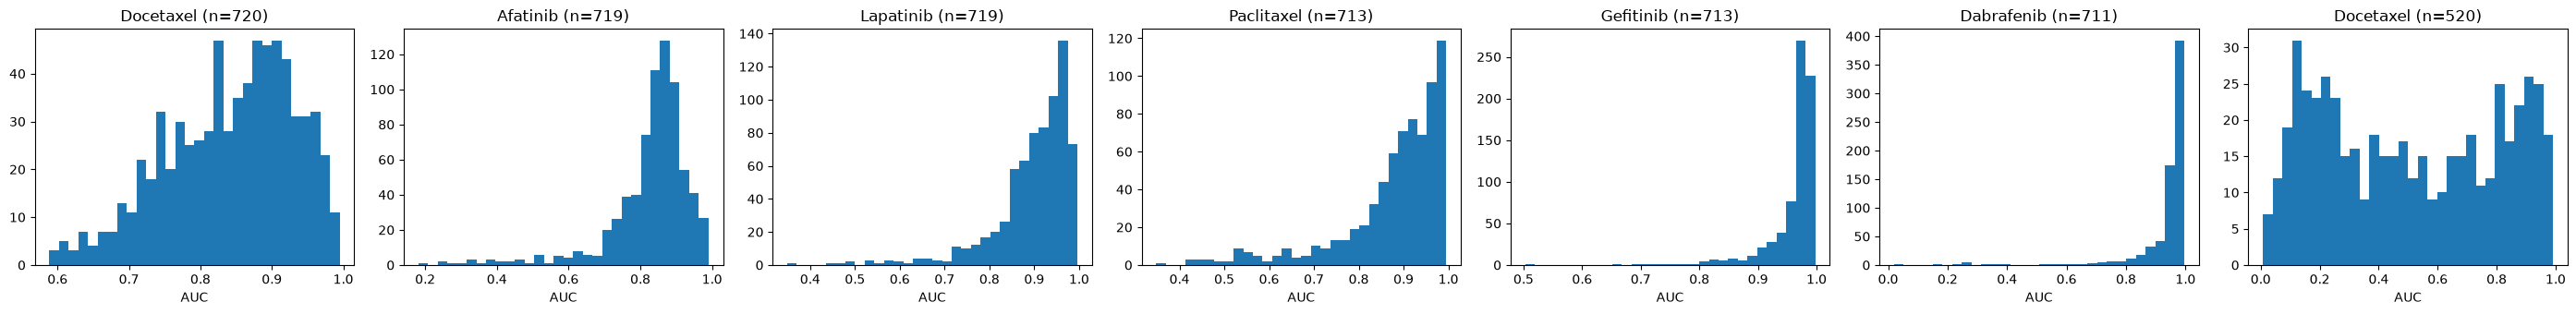

In [48]:
n = len(present)
fig, axes = plt.subplots(1, n, figsize=(4 * n, 3.5), squeeze=False)
for ax, (_, row) in zip(axes[0], present.iterrows()):
    ax.hist(with_expr.loc[with_expr["DRUG_ID"] == row["DRUG_ID"], "AUC"], bins=30)
    ax.set_title(f"{row['DRUG_NAME']} (n={row['n_lines']})")
    ax.set_xlabel("AUC")
plt.tight_layout()
plt.savefig("../reports/figures/candidate_auc_distributions.png", dpi=150)
plt.show()

### tissue balance

In [49]:
chosen_id = present.iloc[0]["DRUG_ID"]   # change to your pick
lineage_counts = (
    with_expr[with_expr["DRUG_ID"] == chosen_id]
    .drop_duplicates("ModelID")["OncotreeLineage"].value_counts()
)
print(lineage_counts)
print("Lineages with < 10 lines:", (lineage_counts < 10).sum())

OncotreeLineage
Lung                         137
Lymphoid                      87
Esophagus/Stomach             51
Breast                        47
Bowel                         42
CNS/Brain                     38
Skin                          38
Ovary/Fallopian Tube          34
Myeloid                       31
Pancreas                      28
Head and Neck                 26
Kidney                        20
Bone                          19
Peripheral Nervous System     19
Bladder/Urinary Tract         16
Uterus                        16
Liver                         14
Thyroid                       13
Cervix                        12
Soft Tissue                   10
Pleura                         7
Prostate                       7
Vulva/Vagina                   2
Biliary Tract                  2
Testis                         2
Adrenal Gland                  1
Fibroblast                     1
Name: count, dtype: int64
Lineages with < 10 lines: 7


## Decision
- **Pipeline:** 969 GDSC2 lines, 966 mapped to Model.csv (3 unmapped), 722 with expression.
- **ID rule:** SIDM00117 maps to NCI-H322 and NCI-H322M; GDSC line lacks expression; excluded.
- **Drug 1 (targeted): Dabrafenib (ID 1373)**, n = 711, AUC std 0.113, mostly resistant with a sensitive tail; expected biomarker BRAF V600E (melanoma).
- **Drug 2 (cytotoxic): Paclitaxel (ID 1080)**, n = 713, AUC std 0.118; no single driver, so it tests the limits of expression-based prediction.
- **Optional extension:** Afatinib (ID 1032), EGFR pathway.
- **Rejected:** Gefitinib (AUC std 0.045, nearly all resistant), Docetaxel 1007 (narrow range), Docetaxel 1819 (different assay condition, fewer lines).
- **Label:** AUC (IC50 is censored at the max tested concentration).
- **Duplicate rule:** no duplicate (drug, cell line) rows; group by DRUG_ID, since names are not unique.
- **Lineage plan:** merge lineages with fewer than 10 lines into "Other" for grouped CV.